# Bedroom Humidity Forecasting


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

## Imports

In [1]:
# preprocessing
from utils import DataCleanPipleLine

# funcs
from utils.useful_funcs import season_decomp, model_vs_reality
from utils.ml_pipeline import *
# viz
import matplotlib.pyplot as plt
import seaborn as sns
from utils import plotting as plot

# files
import os

# time series eda
from statsmodels.tsa.seasonal import STL

# ACF / PACF (numeric values and plots)
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Stationarity tests
from statsmodels.tsa.stattools import adfuller, kpss

# models

# ARIMA / SARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX   # SARIMA = SARIMAX without exog

# Gradient boosting
from xgboost import XGBRegressor

# Random forest and linear regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

## Data Import

In [2]:

# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine
pipe_obj = cleaning_pipeline.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = pipe_obj.RunPipeline(impute_missing_data=True)



****************************************************************************************************
DF Shape: (258083, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure  Humidity
258082  2026-11-17 17:36:05             15.14  961.196700  66.57031
258083  2026-11-17 17:37:05             15.14  961.223400  66.42676
258084  2026-11-17 17:38:05             15.11  961.206400  66.46680
258085  2026-11-17 17:39:06             15.12  961.167700  66.46777
258086  2026-11-17 17:40:06             15.09  961.170100  66.51758
258087  2026-11-17 17:41:06             15.10  961.184680  66.39746
258088  2026-11-17 17:42:06             15.13  961.155664  66.40234
258089  2026-11-17 17:43:06             15.08  961.182200  66.44043
258090  2026-11-17 17:44:06             15.09  961.196700  66.3

## Splitting the data

In [3]:
data_split_dict = train_val_test_split(window_df)

# extract from dict
x_train, x_val, x_test = (
    data_split_dict["x_train"],
    data_split_dict["x_val"],
    data_split_dict["x_test"]
    )

# now targets
y_train, y_val, y_test = (
    data_split_dict["y_train"],
    data_split_dict["y_val"],
    data_split_dict["y_test"]
    )

# get df for eda
train_df = data_split_dict["train_df"]
train_df.head(10)

,Temperature (oC),Pressure,Humidity,DateTime,Sensor_Status,Date,YearMonth,EndOfWeek,Time,Time_Numeric,DailyAvgTemperature,DailyAvgHumidity
2026-03-29 20:54:00+00:00,17.71,999.83000,55.912110,2026-03-29 20:54:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:55:00+00:00,17.68,999.99860,56.043944,2026-03-29 20:55:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:56:00+00:00,17.61,999.81280,55.877930,2026-03-29 20:56:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:57:00+00:00,17.60,999.98488,55.956056,2026-03-29 20:57:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:58:00+00:00,17.61,999.97320,55.732420,2026-03-29 20:58:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:59:00+00:00,17.53,999.97870,55.779296,2026-03-29 20:59:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:00:00+00:00,17.57,1000.03144,55.513670,2026-03-29 21:00:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:01:00+00:00,17.51,1000.08210,55.732420,2026-03-29 21:01:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:02:00+00:00,17.49,1000.09790,55.806640,2026-03-29 21:02:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:03:00+00:00,17.47,1000.14030,55.972656,2026-03-29 21:03:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102


## Time Series Forecasting: Pre-Modelling Analysis

* Distributions
* Trend and seasonality
* Stationarity
* Autocorrelation

In [4]:
train_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 214612 entries, 2026-03-29 20:54:00+00:00 to 2026-08-25 21:45:00+00:00
Freq: min
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     214612 non-null  float64            
 1   Pressure             214612 non-null  float64            
 2   Humidity             214612 non-null  float64            
 3   DateTime             177951 non-null  datetime64[us, UTC]
 4   Sensor_Status        214612 non-null  str                
 5   Date                 214612 non-null  datetime64[s]      
 6   YearMonth            214612 non-null  period[M]          
 7   EndOfWeek            214612 non-null  datetime64[s]      
 8   Time                 214612 non-null  object             
 9   Time_Numeric         214612 non-null  timedelta64[us]    
 10  DailyAvgTemperature  214612 non-null  float64            
 11  DailyAvgHumidity    

### Trend & Seasonality


#### Season Decomposition

1. **Season Decomposition** will be used to understand the overall pattern in Humidity and Temperature. I have chosen this method because of it's simplicity to breakdown timeseries data into 3 components - Trend, Seasonal & Residual.
* Trend - This is simply the rolling average specified by the user.
* Seasonal - Visualises the trend of the data by using subtracting Trend actual observations, then the mean, such as minutely, hourly daily, is then taken from this.
* A prediction can be created by adding Trend & Seasonal together, which is then compared against actual to extract residuals. I can the use the residuals to analyse how well the model performed in generalising the data.

Humidity R2: 0.88


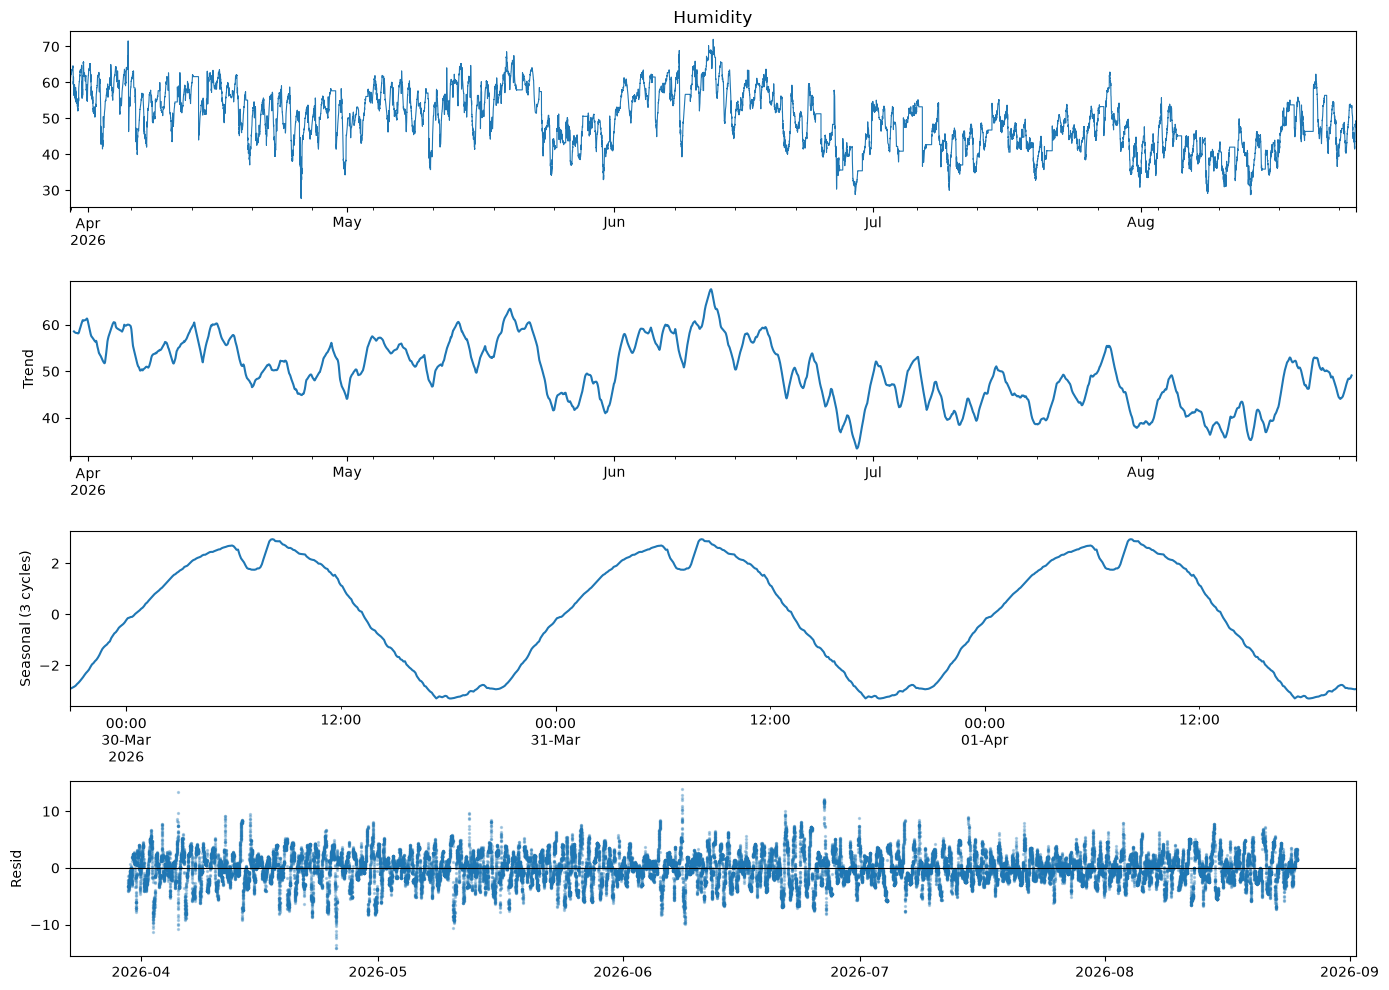

In [5]:
# run seasonal decomposition
feature = ['Humidity']
hum_result = season_decomp(df=train_df[feature],resample_size="5min")


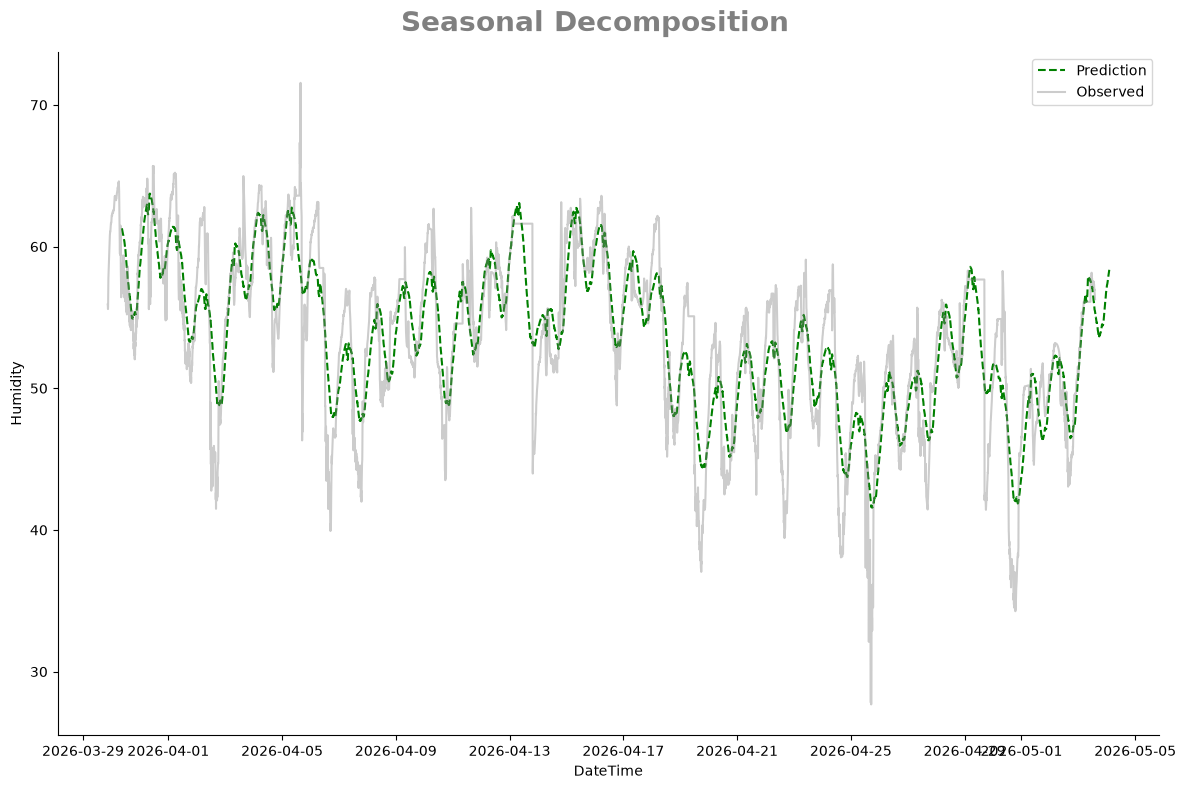

In [6]:
# lets see how the model is against reality
model_vs_reality(model=hum_result, target='Humidity', sample_size=10000)

##### Notes - Humidity Seasonal Decomposition Forecast

1. The model has captured the cycle quite well in that the overall shape of the predicted time series matches to that of the observed. This means that by averaging the difference between trend and observed, the model has captured the daily cycles.
2. However, the model is let down where there are humidity spikes as the predicted lines are +/-10% off the actual - This is the limitation of using mean values as it is being shrunk by the smaller residuals as larger ones appear to be rare.

Temperature (oC) R2: 0.98


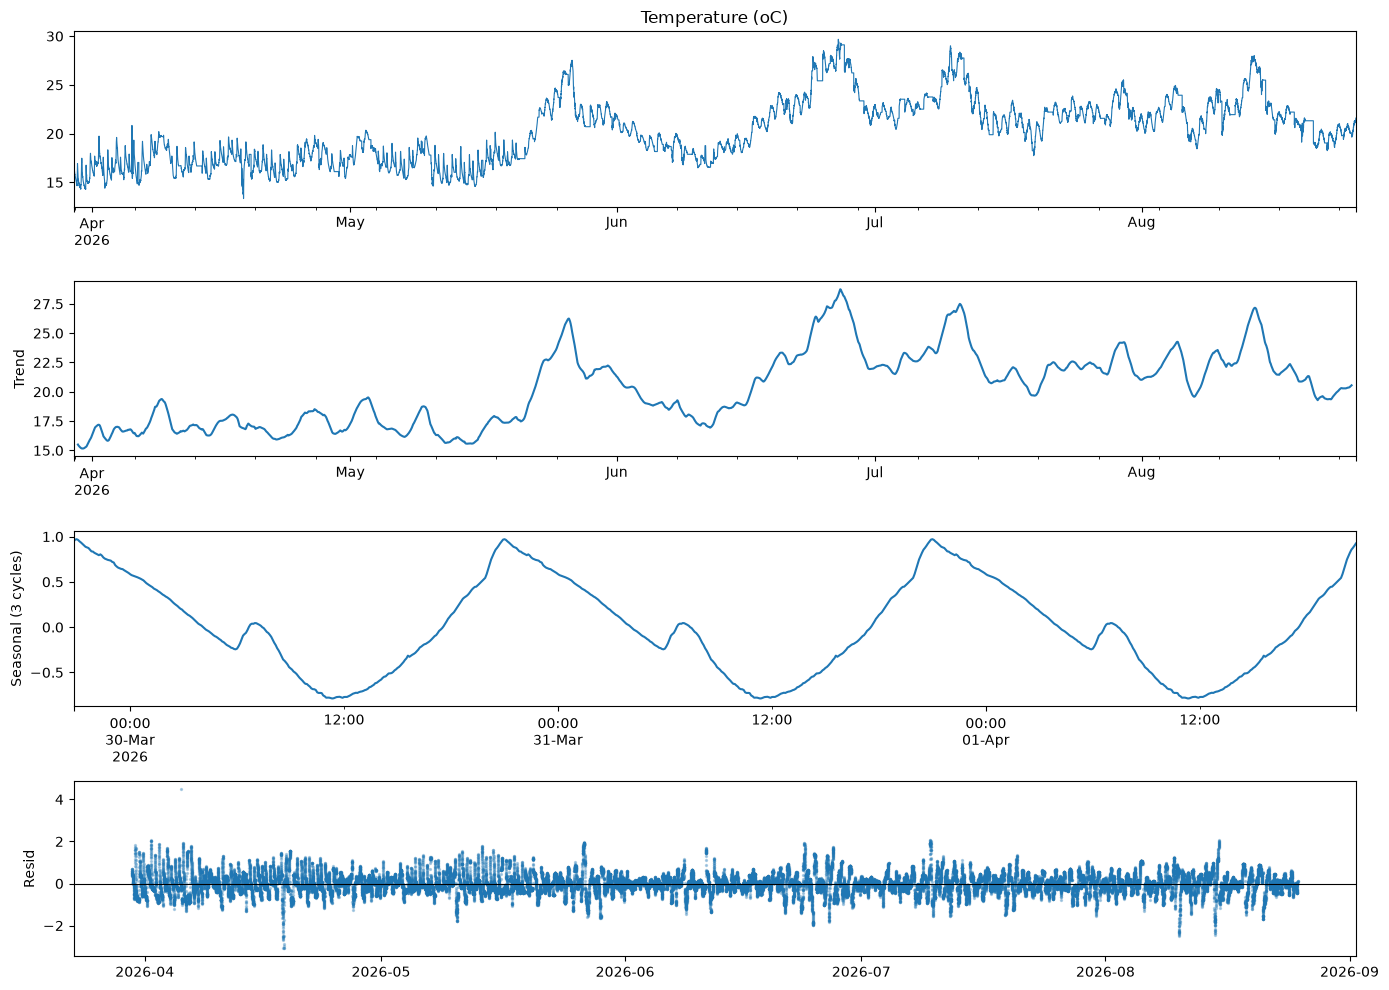

In [7]:
# run seasonal decomposition
feature = ['Temperature (oC)']
tmp_result = season_decomp(df=train_df[feature],resample_size="5min")

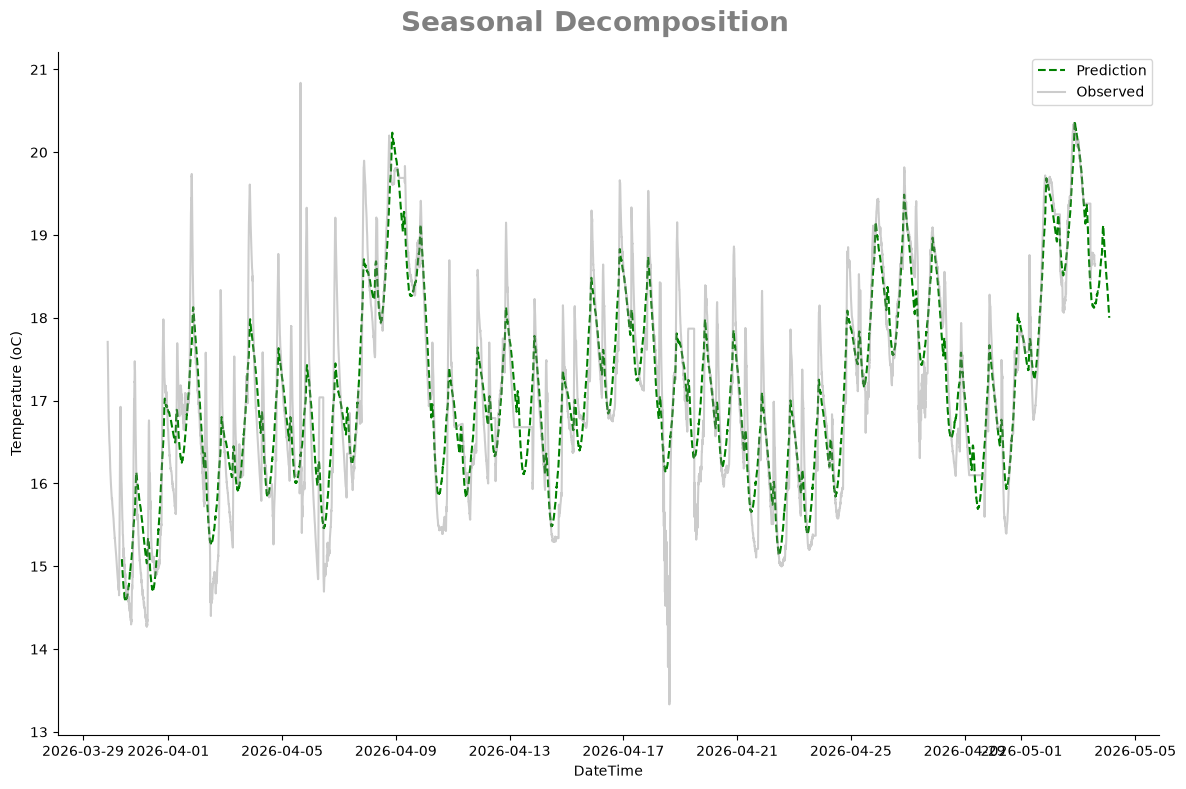

In [8]:
model_vs_reality(model=tmp_result, target='Temperature (oC)', sample_size=10000)

##### Notes - Seasonal Decomposition

1. The seasonal cycles follow a similar pattern as to what I identified in the previous notebook by calculating the hourly median - Humidity peaks early in the morning then the trough is around midday. If I was to reduce condensation in the room, the above and the previous notebook suggests that a dehumidifier should be on early in the morning around 6/7am.
2. The Residual plots show random spikes where the output of the model, potentially identifying where humidity almost breaks predictibility - this could be the imputed data.
3. The residuals over time appear to follow a wave pattern in both positive and negative regions, which means in some days it does ok to predict humidity, while others it was poor. This suggests the Humidity levels on its own breaks a cycle which the model fails to capture well.
4. The trend plot shows a slow declinging humidity levels over time, further supporting my claim of hotter months equates to less humidity.
5. The plot has also identified seasonality, which is unsurpising as this is atmospheric data.

### STL

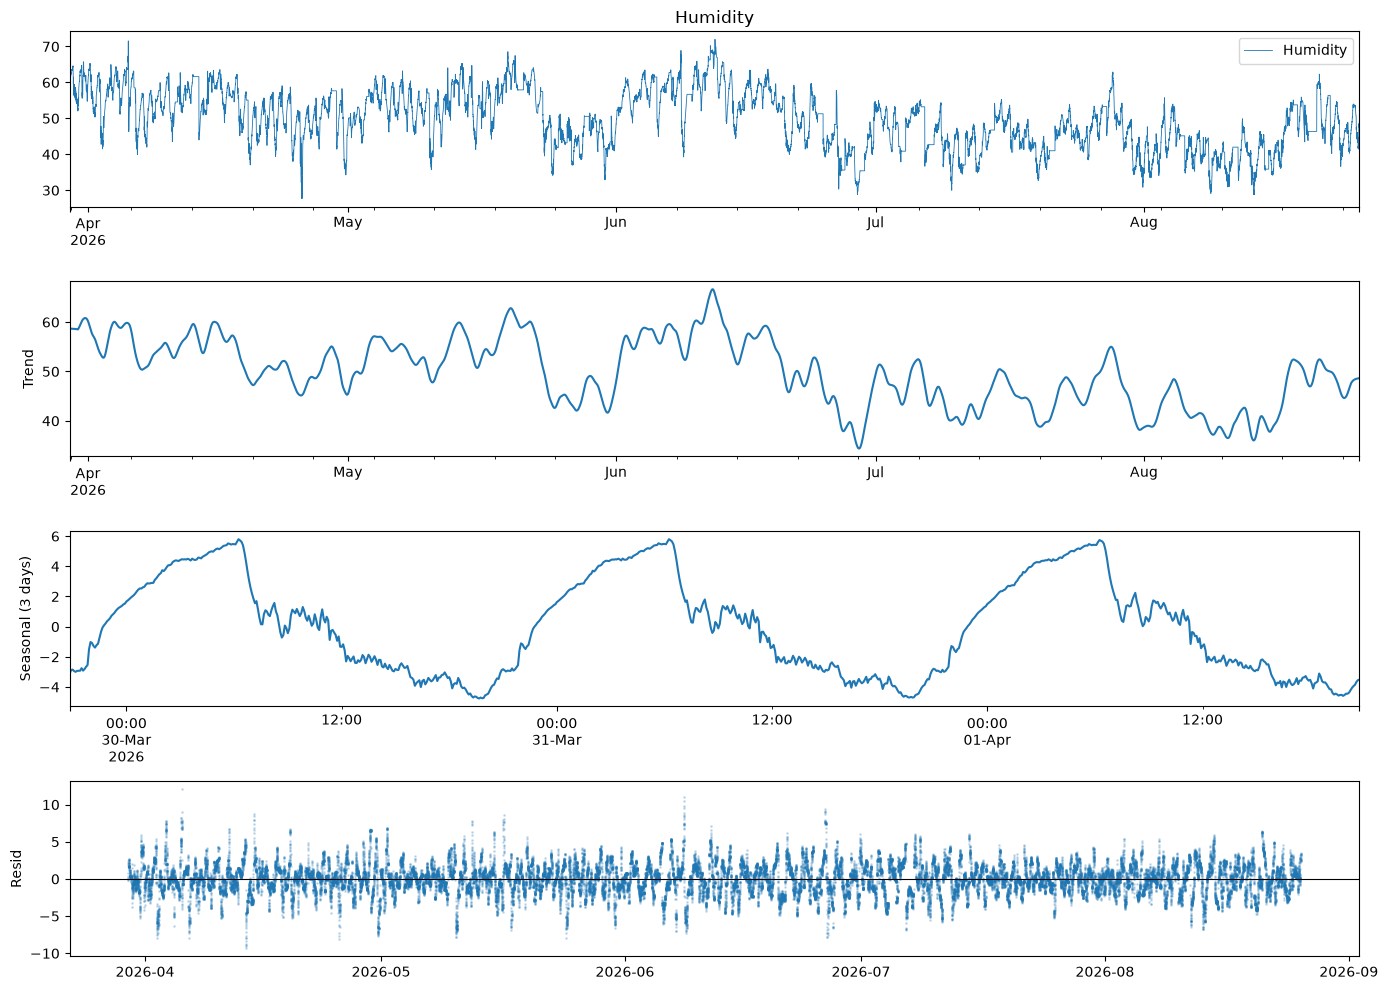

In [ ]:

minutely = "5min"
period = int(pd.Timedelta("1D") / pd.Timedelta(minutely))
# resample the data
hourly_mean = train_df[['Humidity']].resample(minutely).mean()

# fit to data
stl = STL(hourly_mean, period=period)
res = stl.fit()


# plot results
fig, axes = plt.subplots(4, 1, figsize=(14, 10))
res.observed.plot(ax=axes[0], lw=0.6, title="Humidity")
res.trend.plot(ax=axes[1], ylabel="Trend")
res.seasonal.iloc[:period * 3].plot(ax=axes[2], ylabel="Seasonal (3 days)")
axes[3].scatter(res.resid.index, res.resid.values, s=1, alpha=0.2, rasterized=True)
axes[3].axhline(0, color="black", lw=0.8)
axes[3].set_ylabel("Resid")
plt.tight_layout()

### Modelling

* Naive and seasonal naive baselines
* Classical statistical model (ARIMA / SARIMA)
* Machine learning models (lag and rolling features)
* Model comparison and evaluation

### Results